# Classical ML: decision tree, logistic regression, and one-class SVM

All models run on all five saved splits. Text models share the same TF-IDF settings, and seed 0
is used for the displayed ablation and fitted-model inspection. Logistic regression is run twice
as a **feature ablation**: text only versus text plus the compact EDA-motivated feature set.
Hyperparameters are selected with small grouped-CV grids on training rows, thresholds on
validation, and test is evaluated afterward.

In [1]:
import json
import os
import sys
import time
import warnings
from pathlib import Path

if Path.cwd().name == "notebooks":
    os.chdir("..")
sys.path.insert(0, ".")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.dummy import DummyClassifier
from sklearn.metrics import ConfusionMatrixDisplay, PrecisionRecallDisplay

from modules import data_helper as dh
from modules import eval_helper as ev
from modules import explain_helper as eh
from modules import features as ft
from modules import models as md
from modules import results_helper as rh

SEED = 0  # seed used for plots and model inspection
SEEDS = range(5)
OUT = "outputs/classical"
REAL_MODELS = ["logreg_text", "logreg", "tree", "ocsvm"]
RUN_EXPERIMENT = True
N_JOBS = 8  # Adjust to the host; -1 or a positive integer is accepted.

## Data and evaluation split

All preprocessing is fitted by the estimators on training rows (and separately inside each CV fold).
The test rows are displayed here for bookkeeping, not used for feature or parameter selection.

In [2]:
dfe = ft.add_engineered_features(dh.load_processed())
splits = dh.load_splits("splits/seed0.npz", dfe)
train, val, test = (dfe.iloc[splits[name]] for name in ("train", "val", "test"))
y_train = train["fraudulent"].to_numpy()
print({name: {"rows": len(frame), "fraud": int(frame["fraudulent"].sum())}
       for name, frame in (("train", train), ("validation", val), ("test", test))})

{'train': {'rows': 10558, 'fraud': 514}, 'validation': {'rows': 3519, 'fraud': 171}, 'test': {'rows': 3520, 'fraud': 171}}


## Models and small search grids

- **Dummy:** majority class; no training parameters.
- **Decision tree:** `max_depth` and `min_samples_leaf` control overfitting.
- **Logistic regression:** class-balanced, tuning only `C`; run with and without structured features.
- **One-class SVM:** text TF-IDF -> 100-component PCA -> unit-length rows -> RBF SVM. PCA is needed
  here because raw 20,000-dimensional sparse TF-IDF is a poor space for RBF distances. TF-IDF and
  PCA are both fitted on known-real rows only by the detector wrapper.

In [3]:
from sklearn.model_selection import GridSearchCV, ParameterGrid, StratifiedGroupKFold

print("models:", list(md.get_models(SEED)))
print("grid sizes:", {name: len(list(ParameterGrid(grid)))
                      for name, grid in md.PARAM_GRIDS.items()})

models: ['logreg_text', 'logreg', 'tree', 'ocsvm']
grid sizes: {'logreg_text': 3, 'logreg': 3, 'tree': 6, 'ocsvm': 6}


## Run the experiments

Average precision (AP) is the main metric for this imbalanced task. Each non-dummy model uses an
exhaustive small grid with three-fold grouped CV on training. The output folder is reused only when
both files for a finished run exist; use a new output folder after changing the pipeline.

In [4]:
if RUN_EXPERIMENT:
    for experiment_seed in SEEDS:
        dh.seed_everything(experiment_seed)
        run_splits = dh.load_splits(f"splits/seed{experiment_seed}.npz", dfe)
        fit_train, fit_val, fit_test = (
            dfe.iloc[run_splits[name]] for name in ("train", "val", "test")
        )
        y_train, y_val, y_test = (
            part["fraudulent"].to_numpy() for part in (fit_train, fit_val, fit_test)
        )
        print(f"seed {experiment_seed}: rows train/val/test = "
              f"{[len(fit_train), len(fit_val), len(fit_test)]}, positives = "
              f"{[int(y_train.sum()), int(y_val.sum()), int(y_test.sum())]}", flush=True)
        for name in ["dummy_majority", *REAL_MODELS]:
            if rh.result_exists(OUT, name, experiment_seed, fingerprint=dh.data_fingerprint(dfe),
                                val_indices=run_splits["val"], test_indices=run_splits["test"]):
                print(f"seed {experiment_seed} {name}: already done, skipping")
                continue

            start = time.time()
            with warnings.catch_warnings(record=True) as caught:
                warnings.simplefilter("always")
                if name == "dummy_majority":
                    model = DummyClassifier(strategy="most_frequent", random_state=experiment_seed)
                    model.fit(fit_train, y_train)
                    best_params, cv_score = {}, None
                else:
                    folds = StratifiedGroupKFold(
                        n_splits=3, shuffle=True, random_state=experiment_seed
                    )
                    search = GridSearchCV(
                        md.get_models(experiment_seed)[name],
                        md.PARAM_GRIDS[name],
                        scoring="average_precision",
                        cv=folds,
                        n_jobs=N_JOBS,
                        error_score="raise",
                    )
                    search.fit(fit_train, y_train, groups=fit_train["group"].to_numpy())
                    model = search.best_estimator_
                    best_params = search.best_params_
                    cv_score = float(search.best_score_)
            warned = sorted({str(w.message).splitlines()[0][:80] for w in caught})

            score_train, score_val, score_test = (
                ev.score_of(model, part) for part in (fit_train, fit_val, fit_test)
            )
            threshold = 0.5 if name == "dummy_majority" else ev.pick_threshold(y_val, score_val)
            val_metrics = ev.evaluate(y_val, score_val, threshold)
            test_metrics = ev.evaluate(y_test, score_test, threshold)
            seconds = round(time.time() - start, 1)

            if name == "dummy_majority":
                search_desc = "not tuned"
            else:
                candidates = len(ParameterGrid(md.PARAM_GRIDS[name]))
                search_desc = f"{candidates}-candidate grid, 3-fold grouped CV; CV AP {cv_score:.4f}"
            rh.save_result(
                OUT,
                name,
                "classical",
                experiment_seed,
                threshold,
                val_metrics,
                test_metrics,
                y_val,
                score_val,
                y_test,
                score_test,
                train_pr_auc=ev.evaluate(y_train, score_train, threshold)["pr_auc"],
                best_params=best_params,
                seconds=seconds,
                notes=f"{search_desc}; warnings: {warned or 'none'}",
                data_fingerprint=dh.data_fingerprint(dfe),
                val_indices=run_splits["val"], test_indices=run_splits["test"],
            )
            print(
                f"seed {experiment_seed} {name:16s} val AP {val_metrics['pr_auc']:.3f} "
                f"F1 {val_metrics['f1']:.3f} | {seconds}s"
                + (f" | WARNINGS: {'; '.join(warned)}" if warned else ""),
                flush=True,
            )

seed 0: rows train/val/test = [10558, 3519, 3520], positives = [514, 171, 171]


seed 0 dummy_majority: already done, skipping
seed 0 logreg_text: already done, skipping


seed 0 logreg: already done, skipping


seed 0 tree: already done, skipping
seed 0 ocsvm: already done, skipping


seed 1: rows train/val/test = [10558, 3519, 3520], positives = [514, 171, 171]


seed 1 dummy_majority: already done, skipping
seed 1 logreg_text: already done, skipping


... (10 outputs left out)

seed 4: rows train/val/test = [10558, 3519, 3520], positives = [514, 171, 171]


seed 4 dummy_majority: already done, skipping
seed 4 logreg_text: already done, skipping


seed 4 logreg: already done, skipping


seed 4 tree: already done, skipping
seed 4 ocsvm: already done, skipping


In [5]:
results = rh.load_results(OUT)
results = results[results["seed"] == SEED].copy()
assert set(results["model"]) == {"dummy_majority", *REAL_MODELS}
metrics = ["pr_auc", "precision", "recall", "f1"]
comparison = results.set_index("model")[[f"{split}_{metric}" for split in ("val", "test")
                                        for metric in metrics]]
comparison.round(3)

,val_pr_auc,val_precision,val_recall,val_f1,test_pr_auc,test_precision,test_recall,test_f1
model,,,,,,,,
dummy_majority,0.049,0.000,0.000,0.000,0.049,0.000,0.000,0.000
logreg,0.324,0.767,0.269,0.398,0.677,0.908,0.345,0.500
logreg_text,0.294,0.453,0.281,0.347,0.724,0.817,0.550,0.657
ocsvm,0.146,0.298,0.181,0.225,0.044,0.074,0.041,0.053
tree,0.058,0.092,0.345,0.145,0.246,0.294,0.620,0.399


In [6]:
records = {}
for name in ["dummy_majority", *REAL_MODELS]:
    with open(f"{OUT}/{name}_seed{SEED}.json", encoding="utf-8") as f:
        records[name] = json.load(f)
pd.Series({name: str(record["best_params"]) for name, record in records.items()},
          name="selected parameters").to_frame()

,selected parameters
dummy_majority,{}
logreg_text,{'clf__C': 10}
logreg,{'clf__C': 10}
tree,"{'clf__max_depth': None, 'clf__min_samples_lea..."
ocsvm,"{'detector__svm__gamma': 1.0, 'detector__svm__..."


## Does structured feature engineering help logistic regression?

`logreg_text` and `logreg` differ only in the structured feature blocks. Positive differences favour
adding the EDA-motivated features. This comparison is descriptive for the seed-0 split.

In [7]:
delta = comparison.loc["logreg"] - comparison.loc["logreg_text"]
delta.rename("structured minus text-only").round(3).to_frame()

,structured minus text-only
val_pr_auc,0.030
val_precision,0.314
val_recall,-0.012
val_f1,0.052
test_pr_auc,-0.047
test_precision,0.090
test_recall,-0.205
test_f1,-0.157


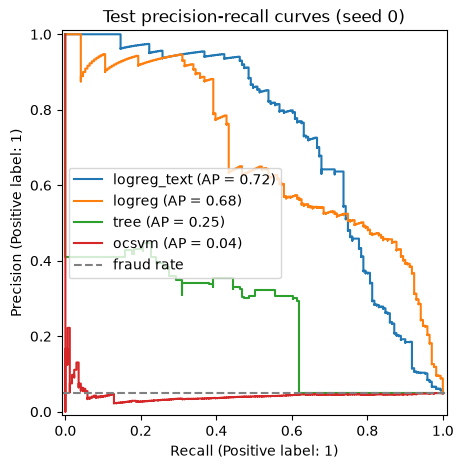

In [8]:
scores = {name: rh.load_scores(OUT, name, SEED) for name in ["dummy_majority", *REAL_MODELS]}
y_test = scores["logreg"]["y_test"]
assert all(np.array_equal(y_test, score["y_test"]) for score in scores.values())

fig, ax = plt.subplots(figsize=(7, 5))
for name in REAL_MODELS:
    PrecisionRecallDisplay.from_predictions(y_test, scores[name]["score_test"], name=name, ax=ax)
ax.axhline(y_test.mean(), color="grey", linestyle="--", label="fraud rate")
ax.set_title("Test precision-recall curves (seed 0)")
ax.legend()
plt.show()

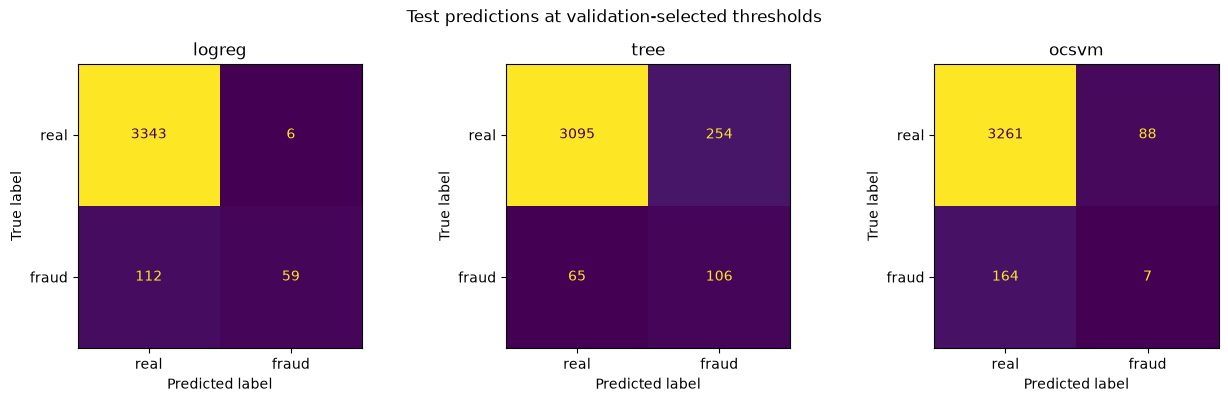

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, name in zip(axes, ["logreg", "tree", "ocsvm"]):
    threshold = records[name]["thr"]
    pred = scores[name]["score_test"] >= threshold
    ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=["real", "fraud"],
                                            colorbar=False, ax=ax)
    ax.set_title(name)
fig.suptitle("Test predictions at validation-selected thresholds")
fig.tight_layout()
plt.show()

## Inspect the fitted supervised models

Refit only on training rows using the saved parameters, solely to recover fitted coefficients and
importances. No new metric is selected from test data.

In [10]:
def refit_for_explanation(name):
    model = md.get_models(SEED)[name].set_params(**records[name]["best_params"])
    return model.fit(train, train["fraudulent"])


logreg = refit_for_explanation("logreg")
eh.top_linear_terms(logreg, k=15)

,term,coef,direction
0,text__link url,5.082870,positive
1,text__money,5.036520,positive
2,text__using link,4.484705,positive
3,text__url,4.423625,positive
4,text__income,4.313316,positive
5,text__link,4.183541,positive
6,text__apply using,4.119493,positive
7,text__earn,4.059237,positive
8,text__hospital,3.824229,positive
9,nominal__industry_Biotechnology,3.810010,positive


In [11]:
tree = refit_for_explanation("tree")
importances = pd.Series(
    tree.named_steps["clf"].feature_importances_,
    index=tree.named_steps["pre"].get_feature_names_out(),
)
importances.nlargest(15).rename("importance").to_frame()

,importance
binary__has_company_profile,0.389473
nominal__required_education_High School or equivalent,0.116418
binary__has_company_logo,0.037432
text__available,0.032116
text__le,0.026511
text__earn,0.026060
nominal__required_experience_Mid-Senior level,0.022244
text__years project,0.018957
text__small business,0.018621
text__professionals,0.017769


In [12]:
y_error = np.asarray(scores["logreg"]["y_val"]).astype(int)
score_error = np.asarray(scores["logreg"]["score_val"], dtype=float)
pred_error = score_error >= records["logreg"]["thr"]
fp_idx = np.where((pred_error == 1) & (y_error == 0))[0]
fn_idx = np.where((pred_error == 0) & (y_error == 1))[0]
fp_idx = fp_idx[np.argsort(-score_error[fp_idx])][:3]
fn_idx = fn_idx[np.argsort(score_error[fn_idx])][:3]
error_rows = []
for kind, indices in (("false_positive", fp_idx), ("false_negative", fn_idx)):
    for i in indices:
        row = val.iloc[i]
        error_rows.append({
            "error_type": kind,
            "score": float(score_error[i]),
            "y_true": int(y_error[i]),
            "title": str(row["title"]),
            "description": str(row["description"])[:200],
        })
for error in error_rows:
    print(f"[{error['error_type']}] score={error['score']:.3f} | {error['title']}")
    print(error["description"], "\n")

[false_positive] score=0.999 | Data Entry
This is a data entry position, Working hours are flexible. you are also expected to come online through Yahoo Messenger during working hours and also for your online interview / job briefing.i will li 

[false_positive] score=0.989 | Accounting/Data entry
Responsibilities :• Responsible for the delivery of outstanding customer service. • Answer inbound communications (phone calls and emails in the future) from individuals regarding general questions, i 

[false_positive] score=0.983 | Part-Time Sales Referral Positions
A national website design and marketing company is looking for self managed and highly motivated people who are interested in set your own hours.  My48HourWebsite creates and manages websites for smal 

[false_negative] score=0.000 | Information Security Manager
This leading-edge company drives over $3 billion in revenue from web sites, search engines, and social networks for more than 8,400 of the world’s top brands.  As a Infor

## Seed-0 audit conclusion

This single split supports logistic regression as the supervised reference, but not a choice between its feature sets. Structured features improve validation AP (+0.030) and F1 (+0.052), while test AP and F1 decrease by 0.047 and 0.157. Do not resolve that disagreement by selecting the better test row. Both logistic variants fit the training text almost perfectly (train AP about 1.0 versus grouped-CV AP 0.61–0.63), and the large validation/test reversals require multi-seed evidence.

The tree reaches higher test recall but much lower precision than logistic regression. The one-class SVM is not a useful detector on this split: test AP 0.044 is below the 0.049 prevalence floor. The printed errors illustrate associations learned from flexible/data-entry language and conventional professional language; individual examples alone do not establish label errors.

**Next:** notebook 03 evaluates top-two-layer and full DistilBERT fine-tuning with text-only and structured-fusion heads on the same five splits. Notebook 04 compares them with the classical baselines using paired deltas and variability. Because EDA used the full dataset and this audit inspected seed-0 test scores, these results are exploratory; a future unbiased headline requires frozen decisions and an untouched final evaluation.